In [1]:
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from pathlib import Path

project_root = Path.cwd().parent
raw_dir = project_root / "data" / "raw"

print("Project root:", project_root)
print("Raw data directory:", raw_dir)

print("\nFolders inside data/raw:")
for item in raw_dir.iterdir():
    print(item.name, "—", "Folder" if item.is_dir() else "File")

Project root: c:\Users\Hey_Nerd\Desktop\plant-disease-classifier
Raw data directory: c:\Users\Hey_Nerd\Desktop\plant-disease-classifier\data\raw

Folders inside data/raw:
Plant_leave_diseases_dataset_without_augmentation — Folder


In [3]:
from pathlib import Path

PROJECT_ROOT = Path(
    r"C:\Users\Hey_Nerd\Desktop\plant-disease-classifier"
)

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

DATA_DIR = (
    RAW_DATA_DIR
    / "Plant_leave_diseases_dataset_without_augmentation"
)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_DIR)
print("Dataset exists:", DATA_DIR.exists())

assert PROJECT_ROOT.exists(), "Project folder not found."
assert DATA_DIR.exists(), "Dataset folder not found."

Project root: C:\Users\Hey_Nerd\Desktop\plant-disease-classifier
Dataset path: C:\Users\Hey_Nerd\Desktop\plant-disease-classifier\data\raw\Plant_leave_diseases_dataset_without_augmentation
Dataset exists: True


In [4]:
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".webp"
}

print("DATASET STRUCTURE")
print("=" * 60)

for item in sorted(DATA_DIR.iterdir()):
    if item.is_dir():
        subfolders = [
            p for p in item.iterdir()
            if p.is_dir()
        ]

        image_count = sum(
            1
            for p in item.rglob("*")
            if p.is_file()
            and p.suffix.lower() in IMAGE_EXTENSIONS
        )

        print(
            f"[FOLDER] {item.name} | "
            f"Subfolders: {len(subfolders)} | "
            f"Images inside: {image_count}"
        )

        for subfolder in subfolders[:5]:
            print(f"    └── {subfolder.name}")

    elif item.is_file():
        print(f"[FILE] {item.name}")

DATASET STRUCTURE
[FOLDER] Apple___Apple_scab | Subfolders: 0 | Images inside: 630
[FOLDER] Apple___Black_rot | Subfolders: 0 | Images inside: 621
[FOLDER] Apple___Cedar_apple_rust | Subfolders: 0 | Images inside: 275
[FOLDER] Apple___healthy | Subfolders: 0 | Images inside: 1645
[FOLDER] Background_without_leaves | Subfolders: 0 | Images inside: 1143
[FOLDER] Blueberry___healthy | Subfolders: 0 | Images inside: 1502
[FOLDER] Cherry___healthy | Subfolders: 0 | Images inside: 854
[FOLDER] Cherry___Powdery_mildew | Subfolders: 0 | Images inside: 1052
[FOLDER] Corn___Cercospora_leaf_spot Gray_leaf_spot | Subfolders: 0 | Images inside: 513
[FOLDER] Corn___Common_rust | Subfolders: 0 | Images inside: 1192
[FOLDER] Corn___healthy | Subfolders: 0 | Images inside: 1162
[FOLDER] Corn___Northern_Leaf_Blight | Subfolders: 0 | Images inside: 985
[FOLDER] Grape___Black_rot | Subfolders: 0 | Images inside: 1180
[FOLDER] Grape___Esca_(Black_Measles) | Subfolders: 0 | Images inside: 1383
[FOLDER] Grap

In [5]:
# Step 3: Dataset summary and class counts

import pandas as pd
from pathlib import Path

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

class_records = []

for class_dir in sorted(DATA_DIR.iterdir()):

    # Each immediate subfolder represents a class
    if not class_dir.is_dir():
        continue

    image_paths = [
        path for path in class_dir.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    if not image_paths:
        continue

    class_name = class_dir.name

    # Separate the plant name and condition when possible
    if "___" in class_name:
        plant_name, disease_name = class_name.split("___", 1)
    else:
        plant_name = class_name
        disease_name = "Unspecified"

    class_records.append({
        "class_name": class_name,
        "plant_name": plant_name,
        "disease_name": disease_name,
        "image_count": len(image_paths),
        "folder_path": str(class_dir)
    })

class_summary = pd.DataFrame(class_records)

if class_summary.empty:
    raise ValueError(
        "No images found. Check the DATA_DIR path."
    )

class_summary = (
    class_summary
    .sort_values("image_count", ascending=False)
    .reset_index(drop=True)
)

total_images = int(class_summary["image_count"].sum())
total_classes = len(class_summary)

print(f"Total images: {total_images:,}")
print(f"Total classes: {total_classes}")
print(f"Average images per class: "
      f"{class_summary['image_count'].mean():.2f}")
print(f"Median images per class: "
      f"{class_summary['image_count'].median():.0f}")
print(f"Minimum images in a class: "
      f"{class_summary['image_count'].min():,}")
print(f"Maximum images in a class: "
      f"{class_summary['image_count'].max():,}")

display(class_summary)

Total images: 55,448
Total classes: 39
Average images per class: 1421.74
Median images per class: 1109
Minimum images in a class: 152
Maximum images in a class: 5,507


,class_name,plant_name,disease_name,image_count,folder_path
0,Orange___Haunglongbing_(Citrus_greening),Orange,Haunglongbing_(Citrus_greening),5507,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
1,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato,Tomato_Yellow_Leaf_Curl_Virus,5357,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
2,Soybean___healthy,Soybean,healthy,5090,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
3,Peach___Bacterial_spot,Peach,Bacterial_spot,2297,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
4,Tomato___Bacterial_spot,Tomato,Bacterial_spot,2127,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
5,Tomato___Late_blight,Tomato,Late_blight,1909,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
6,Squash___Powdery_mildew,Squash,Powdery_mildew,1835,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
7,Tomato___Septoria_leaf_spot,Tomato,Septoria_leaf_spot,1771,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
8,Tomato___Spider_mites Two-spotted_spider_mite,Tomato,Spider_mites Two-spotted_spider_mite,1676,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
9,Apple___healthy,Apple,healthy,1645,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...


In [6]:
# Save the dataset summary for future reference

REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

summary_path = REPORTS_DIR / "class_distribution.csv"

class_summary.to_csv(summary_path, index=False)

print("Summary saved to:", summary_path)

Summary saved to: C:\Users\Hey_Nerd\Desktop\plant-disease-classifier\reports\class_distribution.csv


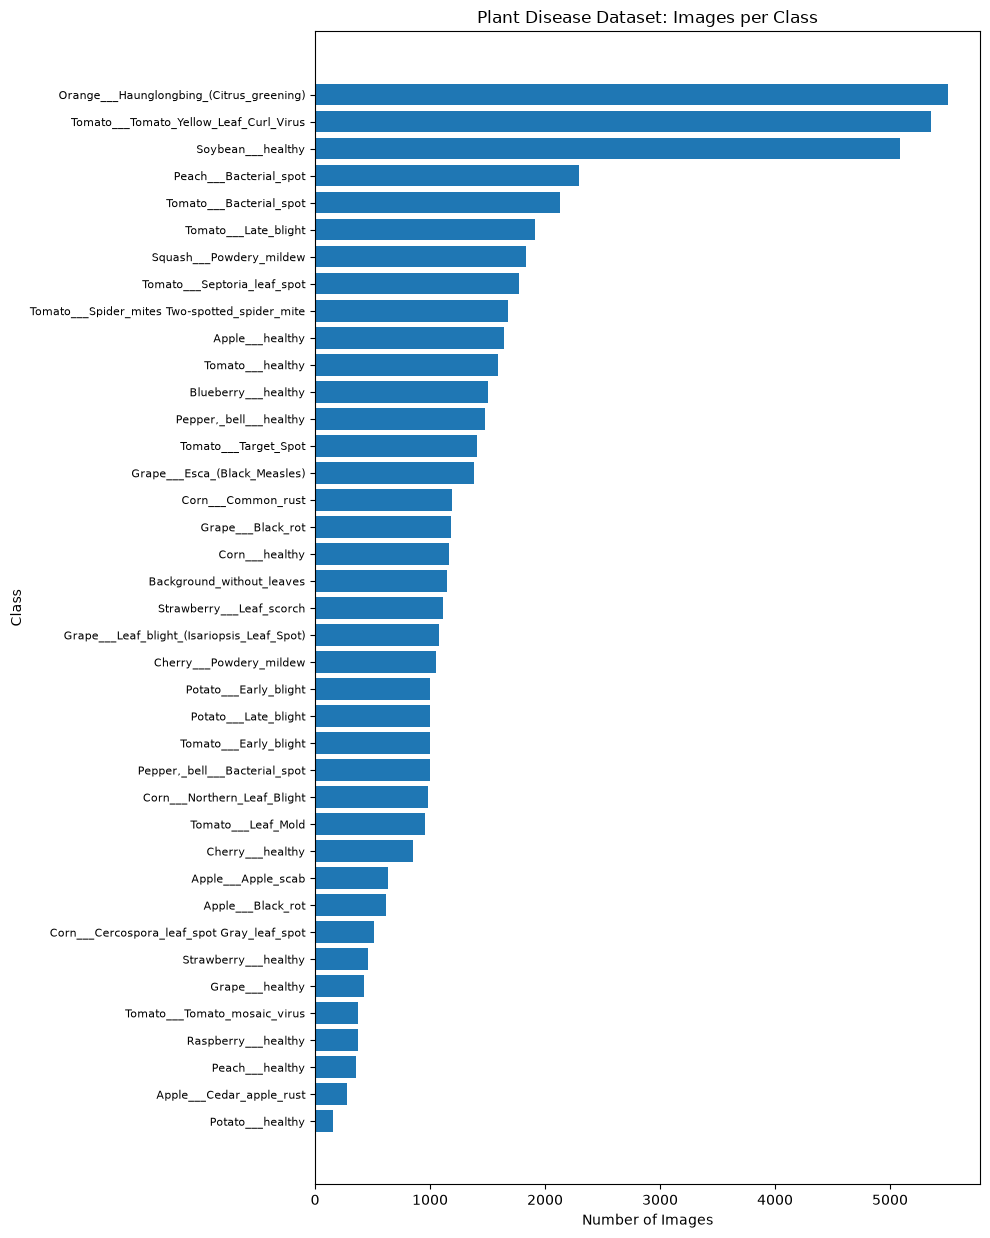

Chart saved to: C:\Users\Hey_Nerd\Desktop\plant-disease-classifier\reports\class_distribution.png


In [14]:
# Plot all classes, ordered by image count

plot_data = class_summary.sort_values(
    "image_count",
    ascending=True
)

plt.figure(
    figsize=(10, max(10, len(plot_data) * 0.32))
)

plt.barh(
    plot_data["class_name"],
    plot_data["image_count"]
)

plt.title("Plant Disease Dataset: Images per Class")
plt.xlabel("Number of Images")
plt.ylabel("Class")
plt.tick_params(axis="y", labelsize=8)

plt.tight_layout()

chart_path = REPORTS_DIR / "class_distribution.png"

plt.savefig(
    chart_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Chart saved to:", chart_path)

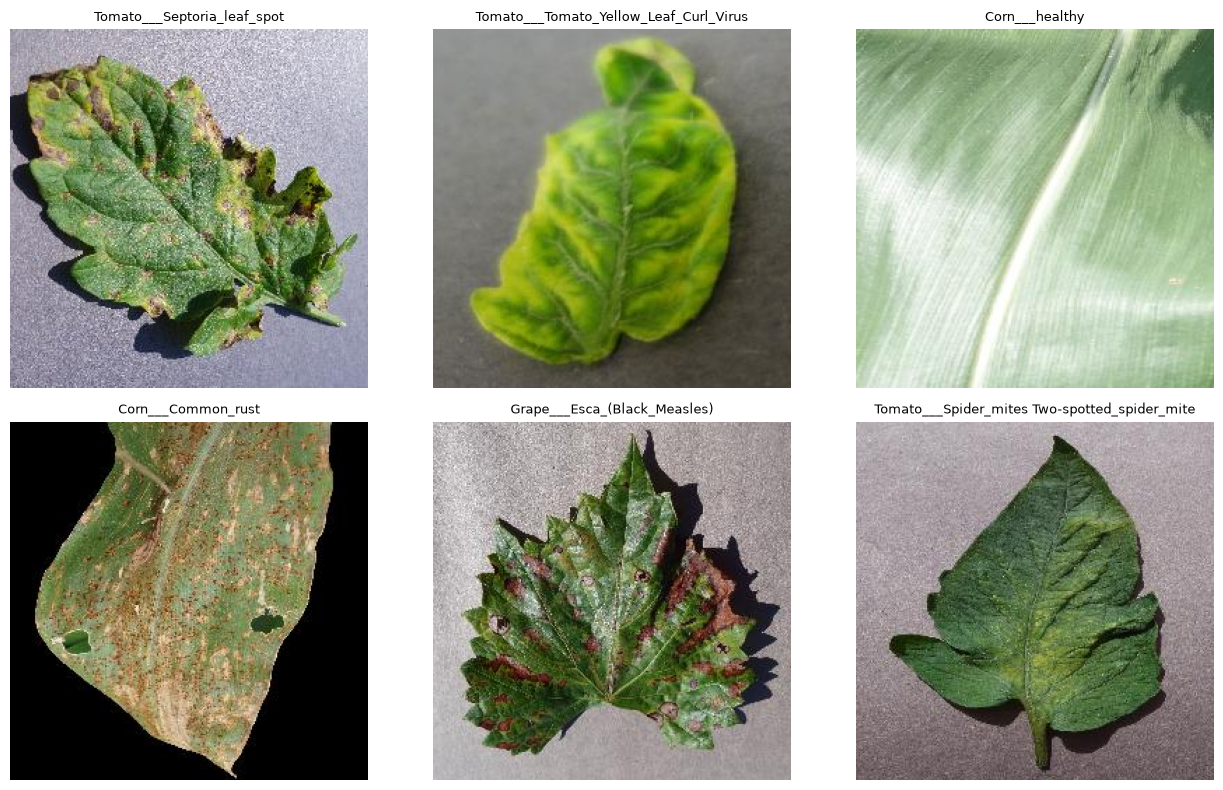

In [15]:
import random
import matplotlib.pyplot as plt
from PIL import Image

RANDOM_SEED = 42
rng = random.Random(RANDOM_SEED)

# Sample six different classes
number_of_samples = min(6, len(class_summary))

sample_classes = rng.sample(
    class_summary["class_name"].tolist(),
    number_of_samples
)

fig, axes = plt.subplots(
    2, 3,
    figsize=(13, 8)
)

axes = axes.flatten()

for ax, class_name in zip(axes, sample_classes):

    class_dir = DATA_DIR / class_name

    image_paths = [
        path for path in class_dir.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    image_path = rng.choice(image_paths)

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(class_name, fontsize=9)
    ax.axis("off")

for ax in axes[number_of_samples:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
from collections import Counter

rng = random.Random(RANDOM_SEED)

dimension_counts = Counter()
color_mode_counts = Counter()
sampled_images = 0
read_errors = []

for class_name in class_summary["class_name"]:

    class_dir = DATA_DIR / class_name

    image_paths = [
        path for path in class_dir.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    selected_paths = rng.sample(
        image_paths,
        min(10, len(image_paths))
    )

    for image_path in selected_paths:
        try:
            with Image.open(image_path) as image:
                dimension_counts[image.size] += 1
                color_mode_counts[image.mode] += 1
                sampled_images += 1

        except Exception as error:
            read_errors.append({
                "path": str(image_path),
                "error": str(error)
            })

print("Images inspected:", sampled_images)

print("\nMost common original image dimensions:")
for dimensions, count in dimension_counts.most_common(10):
    print(f"{dimensions}: {count}")

print("\nColor modes:")
for mode, count in color_mode_counts.items():
    print(f"{mode}: {count}")

print("\nRead errors in this sample:", len(read_errors))

Images inspected: 390

Most common original image dimensions:
(256, 256): 380
(256, 192): 10

Color modes:
RGB: 390

Read errors in this sample: 0


In [17]:
# Step 7: Full dataset image integrity audit

from PIL import Image
import pandas as pd

all_image_paths = [
    path
    for path in DATA_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in IMAGE_EXTENSIONS
]

valid_records = []
error_records = []

total_files = len(all_image_paths)

print(f"Images to inspect: {total_files:,}")

for index, image_path in enumerate(all_image_paths, start=1):
    try:
        with Image.open(image_path) as image:
            image.load()

            width, height = image.size
            color_mode = image.mode
            image_format = image.format

        valid_records.append({
            "file_path": str(image_path),
            "class_name": image_path.relative_to(
                DATA_DIR
            ).parts[0],
            "width": width,
            "height": height,
            "color_mode": color_mode,
            "image_format": image_format,
            "file_size_kb": round(
                image_path.stat().st_size / 1024, 2
            )
        })

    except Exception as error:
        error_records.append({
            "file_path": str(image_path),
            "error_type": type(error).__name__,
            "error_message": str(error)
        })

    if index % 5000 == 0 or index == total_files:
        print(f"Checked {index:,} / {total_files:,} images")

# Create report DataFrames
df_valid_images = pd.DataFrame(valid_records)
df_image_errors = pd.DataFrame(error_records)

print("\nIMAGE AUDIT SUMMARY")
print("=" * 45)
print(f"Total files found: {total_files:,}")
print(f"Images loaded successfully: {len(df_valid_images):,}")
print(f"Images with read errors: {len(df_image_errors):,}")

if total_files:
    print(
        f"Successful read rate: "
        f"{len(df_valid_images) / total_files * 100:.2f}%"
    )

# Save results
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

df_valid_images.to_csv(
    REPORTS_DIR / "image_quality_audit.csv",
    index=False
)

df_image_errors.to_csv(
    REPORTS_DIR / "image_read_errors.csv",
    index=False
)

print("\nAudit reports saved in:", REPORTS_DIR)

Images to inspect: 55,448
Checked 5,000 / 55,448 images
Checked 10,000 / 55,448 images
Checked 15,000 / 55,448 images
Checked 20,000 / 55,448 images
Checked 25,000 / 55,448 images
Checked 30,000 / 55,448 images
Checked 35,000 / 55,448 images
Checked 40,000 / 55,448 images
Checked 45,000 / 55,448 images
Checked 50,000 / 55,448 images
Checked 55,000 / 55,448 images
Checked 55,448 / 55,448 images

IMAGE AUDIT SUMMARY
Total files found: 55,448
Images loaded successfully: 55,448
Images with read errors: 0
Successful read rate: 100.00%

Audit reports saved in: C:\Users\Hey_Nerd\Desktop\plant-disease-classifier\reports


In [18]:
# Inspect dimensions and image modes across valid images

if not df_valid_images.empty:
    print("Most common image dimensions:")
    display(
        df_valid_images
        .groupby(["width", "height"])
        .size()
        .sort_values(ascending=False)
        .head(10)
        .rename("image_count")
        .reset_index()
    )

    print("\nColor mode distribution:")
    display(
        df_valid_images["color_mode"]
        .value_counts()
        .rename_axis("color_mode")
        .reset_index(name="image_count")
    )

    print("\nImage format distribution:")
    display(
        df_valid_images["image_format"]
        .value_counts()
        .rename_axis("image_format")
        .reset_index(name="image_count")
    )

Most common image dimensions:


,width,height,image_count
0,256,256,54305
1,256,192,1143



Color mode distribution:


,color_mode,image_count
0,RGB,55447
1,RGBA,1



Image format distribution:


,image_format,image_count
0,JPEG,55447
1,PNG,1


In [19]:
# Step 7.1: Image dimensions by class

dimensions_by_class = pd.crosstab(
    df_valid_images["class_name"],
    [
        df_valid_images["width"],
        df_valid_images["height"]
    ]
)

print("Image dimensions by class:")
display(dimensions_by_class)

Image dimensions by class:


width                                           256      
height                                          192   256
class_name                                               
Apple___Apple_scab                                0   630
Apple___Black_rot                                 0   621
Apple___Cedar_apple_rust                          0   275
Apple___healthy                                   0  1645
Background_without_leaves                      1143     0
Blueberry___healthy                               0  1502
Cherry___Powdery_mildew                           0  1052
Cherry___healthy                                  0   854
Corn___Cercospora_leaf_spot Gray_leaf_spot        0   513
Corn___Common_rust                                0  1192
Corn___Northern_Leaf_Blight                       0   985
Corn___healthy                                    0  1162
Grape___Black_rot                                 0  1180
Grape___Esca_(Black_Measles)                      0  1383
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)        0  1076
Grape___healthy                                   0   423
Orange___Haunglongbing_(Citrus_greening)          0  5507
Peach___Bacterial_spot                            0  2297
Peach___healthy                                   0   360
Pepper,_bell___Bacterial_spot                     0   997
Pepper,_bell___healthy                            0  1478
Potato___Early_blight                             0  1000
Potato___Late_blight                              0  1000
Potato___healthy                                  0   152
Raspberry___healthy                               0   371
Soybean___healthy                                 0  5090
Squash___Powdery_mildew                           0  1835
Strawberry___Leaf_scorch                          0  1109
Strawberry___healthy                              0   456
Tomato___Bacterial_spot                           0  2127
Tomato___Early_blight                             0  1000
Tomato___Late_blight                              0  1909
Tomato___Leaf_Mold                                0   952
Tomato___Septoria_leaf_spot                       0  1771
Tomato___Spider_mites Two-spotted_spider_mite     0  1676
Tomato___Target_Spot                              0  1404
Tomato___Tomato_Yellow_Leaf_Curl_Virus            0  5357
Tomato___Tomato_mosaic_virus                      0   373
Tomato___healthy                                  0  1591

In [20]:
# Step 7.2: Inspect rectangular images

rectangular_images = df_valid_images[
    df_valid_images["width"]
    != df_valid_images["height"]
]

print("Number of rectangular images:",
      len(rectangular_images))

print("\nRectangular images by class:")

display(
    rectangular_images["class_name"]
    .value_counts()
    .rename_axis("class_name")
    .reset_index(name="image_count")
)

Number of rectangular images: 1143

Rectangular images by class:


,class_name,image_count
0,Background_without_leaves,1143


In [21]:
# Step 7.3: Inspect non-RGB images

non_rgb_images = df_valid_images[
    df_valid_images["color_mode"] != "RGB"
]

display(
    non_rgb_images[
        [
            "file_path",
            "class_name",
            "width",
            "height",
            "color_mode",
            "image_format"
        ]
    ]
)

,file_path,class_name,width,height,color_mode,image_format
24798,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...,"Pepper,_bell___healthy",256,256,RGBA,PNG


## 8. Exact Duplicate Detection

In [22]:
# Step 8: Detect exact duplicate images using SHA-256

import hashlib
import pandas as pd
from pathlib import Path

def calculate_sha256(file_path, chunk_size=1024 * 1024):
    """Calculate a file's SHA-256 hash without reading it all at once."""
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        while True:
            chunk = file.read(chunk_size)

            if not chunk:
                break

            sha256.update(chunk)

    return sha256.hexdigest()


hash_records = []
hash_errors = []

total_files = len(df_valid_images)

print(f"Starting duplicate audit for {total_files:,} images...")

for index, row in enumerate(
    df_valid_images[["file_path", "class_name"]].itertuples(
        index=False, name=None
    ),
    start=1
):
    file_path, class_name = row

    try:
        file_hash = calculate_sha256(file_path)

        hash_records.append({
            "file_path": file_path,
            "class_name": class_name,
            "sha256": file_hash
        })

    except Exception as error:
        hash_errors.append({
            "file_path": file_path,
            "error": str(error)
        })

    if index % 5000 == 0 or index == total_files:
        print(f"Processed {index:,} / {total_files:,} images")


df_hashes = pd.DataFrame(hash_records)

print("\nHashing completed.")
print("Files hashed successfully:", len(df_hashes))
print("Files with hashing errors:", len(hash_errors))

Starting duplicate audit for 55,448 images...
Processed 5,000 / 55,448 images
Processed 10,000 / 55,448 images
Processed 15,000 / 55,448 images
Processed 20,000 / 55,448 images
Processed 25,000 / 55,448 images
Processed 30,000 / 55,448 images
Processed 35,000 / 55,448 images
Processed 40,000 / 55,448 images
Processed 45,000 / 55,448 images
Processed 50,000 / 55,448 images
Processed 55,000 / 55,448 images
Processed 55,448 / 55,448 images

Hashing completed.
Files hashed successfully: 55448
Files with hashing errors: 0


In [23]:
# Identify all files whose hash appears more than once

duplicate_files = df_hashes[
    df_hashes.duplicated(
        subset="sha256",
        keep=False
    )
].copy()

if duplicate_files.empty:
    duplicate_groups = pd.DataFrame(
        columns=[
            "sha256",
            "file_count",
            "class_count",
            "classes",
            "file_paths"
        ]
    )

else:
    duplicate_groups = (
        duplicate_files
        .groupby("sha256")
        .agg(
            file_count=("file_path", "size"),
            class_count=("class_name", "nunique"),
            classes=(
                "class_name",
                lambda values: " | ".join(sorted(set(values)))
            ),
            file_paths=(
                "file_path",
                lambda values: " | ".join(values)
            )
        )
        .reset_index()
    )

print("DUPLICATE AUDIT SUMMARY")
print("=" * 45)
print("Successfully hashed files:", len(df_hashes))
print("Exact duplicate groups:", len(duplicate_groups))
print("Files participating in duplicate groups:", len(duplicate_files))

cross_class_duplicates = duplicate_groups[
    duplicate_groups["class_count"] > 1
]

print(
    "Duplicate groups spanning multiple classes:",
    len(cross_class_duplicates)
)

display(duplicate_groups.head(20))

DUPLICATE AUDIT SUMMARY
Successfully hashed files: 55448
Exact duplicate groups: 22
Files participating in duplicate groups: 45
Duplicate groups spanning multiple classes: 0


,sha256,file_count,class_count,classes,file_paths
0,12852b3616bcf0ba39b03b5677e74f50f5f6abf4d38957...,2,1,Tomato___healthy,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
1,262198126fd6d982126b69261723e13abb36b383138797...,2,1,Apple___healthy,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
2,2a05a74db3a270ac0ec77c00ebe89a332eed5898194351...,2,1,Tomato___healthy,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
3,2aeb7479e975df37dfb54aa7b403f57f2ad90b018c3780...,2,1,Tomato___Late_blight,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
4,307f49833f5eb2038d44c3374f475c60346c9bcb98de4f...,3,1,Background_without_leaves,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
5,32e9ffabaa054c19ae8df95e94fbd7a25105defdea1214...,2,1,Tomato___healthy,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
6,372bc4a6e18895011eaa18638acf8cdd83db9c5909af02...,2,1,Apple___healthy,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
7,375eee7b5da77c7afdd73d089574bee3148d04cbe266ee...,2,1,Tomato___Late_blight,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
8,3a60a7b6f3a287981d21dca37f27e5480cc46d1144688d...,2,1,Tomato___Late_blight,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...
9,4913a3835e692530e507d542caccacc0d0a7b2fd708782...,2,1,Tomato___Late_blight,C:\Users\Hey_Nerd\Desktop\plant-disease-classi...


In [24]:
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

duplicate_groups.to_csv(
    REPORTS_DIR / "exact_duplicate_groups.csv",
    index=False
)

duplicate_files.to_csv(
    REPORTS_DIR / "exact_duplicate_files.csv",
    index=False
)

pd.DataFrame(hash_errors).to_csv(
    REPORTS_DIR / "hashing_errors.csv",
    index=False
)

print("Duplicate reports saved to:", REPORTS_DIR)

Duplicate reports saved to: C:\Users\Hey_Nerd\Desktop\plant-disease-classifier\reports


In [25]:
# Step 8.1: Review duplicate audit results

from pathlib import Path
import pandas as pd

REPORTS_DIR = PROJECT_ROOT / "reports"

duplicate_groups_path = (
    REPORTS_DIR / "exact_duplicate_groups.csv"
)

duplicate_files_path = (
    REPORTS_DIR / "exact_duplicate_files.csv"
)

duplicate_groups = pd.read_csv(duplicate_groups_path)
duplicate_files = pd.read_csv(duplicate_files_path)

print("DUPLICATE AUDIT RESULTS")
print("=" * 45)

print("Exact duplicate groups:", len(duplicate_groups))
print(
    "Files participating in duplicate groups:",
    len(duplicate_files)
)

if not duplicate_groups.empty:
    cross_class = duplicate_groups[
        duplicate_groups["class_count"] > 1
    ]

    print(
        "Duplicate groups across multiple classes:",
        len(cross_class)
    )

    print("\nSample duplicate groups:")
    display(
        duplicate_groups[
            [
                "file_count",
                "class_count",
                "classes"
            ]
        ].head(10)
    )
else:
    print("No exact duplicate groups were found.")

DUPLICATE AUDIT RESULTS
Exact duplicate groups: 22
Files participating in duplicate groups: 45
Duplicate groups across multiple classes: 0

Sample duplicate groups:


,file_count,class_count,classes
0,2,1,Tomato___healthy
1,2,1,Apple___healthy
2,2,1,Tomato___healthy
3,2,1,Tomato___Late_blight
4,3,1,Background_without_leaves
5,2,1,Tomato___healthy
6,2,1,Apple___healthy
7,2,1,Tomato___Late_blight
8,2,1,Tomato___Late_blight
9,2,1,Tomato___Late_blight


## 9. Deduplication and Dataset Splitting

In [26]:
# Step 9A: Create a unique-image manifest

import pandas as pd
from pathlib import Path

# Confirm that every image in the audit was hashed successfully
if len(df_hashes) != len(df_valid_images):
    raise ValueError(
        "Not all valid images were hashed. "
        "Resolve hashing errors before proceeding."
    )

# Check that exact duplicates do not have conflicting labels
labels_per_hash = (
    df_hashes.groupby("sha256")["class_name"].nunique()
)

conflicting_hashes = labels_per_hash[
    labels_per_hash > 1
]

if not conflicting_hashes.empty:
    raise ValueError(
        "Some exact duplicates have conflicting class labels. "
        "Investigate them before splitting."
    )

# Keep one representative for each unique image
unique_images = (
    df_hashes
    .sort_values("file_path")
    .drop_duplicates(subset="sha256", keep="first")
    .reset_index(drop=True)
)

removed_copies = len(df_hashes) - len(unique_images)

print("DEDUPLICATION SUMMARY")
print("=" * 40)
print("Successfully hashed images:", len(df_hashes))
print("Unique images retained:", len(unique_images))
print("Redundant copies excluded:", removed_copies)
print("Unique classes:", unique_images["class_name"].nunique())

# Save the manifest without modifying any original images
SPLITS_DIR = PROJECT_ROOT / "data" / "splits"
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

unique_images.to_csv(
    SPLITS_DIR / "all_unique_images.csv",
    index=False
)

print("\nManifest saved to:")
print(SPLITS_DIR / "all_unique_images.csv")

DEDUPLICATION SUMMARY
Successfully hashed images: 55448
Unique images retained: 55425
Redundant copies excluded: 23
Unique classes: 39

Manifest saved to:
C:\Users\Hey_Nerd\Desktop\plant-disease-classifier\data\splits\all_unique_images.csv


In [27]:
# Step 9B: Stratified 70/15/15 split

from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

# Split 70% for training and 30% for validation + testing
train_df, remaining_df = train_test_split(
    unique_images,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=unique_images["class_name"]
)

# Divide the remaining 30% equally into validation and testing
val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=remaining_df["class_name"]
)

print("DATA SPLIT SUMMARY")
print("=" * 40)

total = len(unique_images)

for split_name, split_df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    percentage = len(split_df) / total * 100

    print(
        f"{split_name:12s}: "
        f"{len(split_df):,} images ({percentage:.2f}%)"
    )

print("Total:", len(train_df) + len(val_df) + len(test_df))

DATA SPLIT SUMMARY
Training    : 38,797 images (70.00%)
Validation  : 8,314 images (15.00%)
Testing     : 8,314 images (15.00%)
Total: 55425


In [28]:
# Step 9C: Verify split integrity

train_hashes = set(train_df["sha256"])
val_hashes = set(val_df["sha256"])
test_hashes = set(test_df["sha256"])

assert train_hashes.isdisjoint(val_hashes)
assert train_hashes.isdisjoint(test_hashes)
assert val_hashes.isdisjoint(test_hashes)

assert (
    len(train_df) + len(val_df) + len(test_df)
    == len(unique_images)
)

assert (
    train_df["class_name"].nunique()
    == unique_images["class_name"].nunique()
)

assert (
    val_df["class_name"].nunique()
    == unique_images["class_name"].nunique()
)

assert (
    test_df["class_name"].nunique()
    == unique_images["class_name"].nunique()
)

print("All split integrity checks passed.")
print("No exact duplicate images occur across splits.")
print("All classes are represented in all three splits.")

All split integrity checks passed.
No exact duplicate images occur across splits.
All classes are represented in all three splits.


In [29]:
# Step 9D: Export reproducible split manifests

train_df.to_csv(
    SPLITS_DIR / "train.csv",
    index=False
)

val_df.to_csv(
    SPLITS_DIR / "validation.csv",
    index=False
)

test_df.to_csv(
    SPLITS_DIR / "test.csv",
    index=False
)

# Combined manifest for reporting and analysis
train_export = train_df.assign(split="train")
val_export = val_df.assign(split="validation")
test_export = test_df.assign(split="test")

all_splits = pd.concat(
    [train_export, val_export, test_export],
    ignore_index=True
)

all_splits.to_csv(
    SPLITS_DIR / "all_splits.csv",
    index=False
)

print("Split manifests saved to:", SPLITS_DIR)

Split manifests saved to: C:\Users\Hey_Nerd\Desktop\plant-disease-classifier\data\splits


## 10. Final Dataset Split Verification

In [30]:
import pandas as pd
from pathlib import Path

# Load the saved manifests from disk
SPLITS_DIR = PROJECT_ROOT / "data" / "splits"

train_df = pd.read_csv(SPLITS_DIR / "train.csv")
val_df = pd.read_csv(SPLITS_DIR / "validation.csv")
test_df = pd.read_csv(SPLITS_DIR / "test.csv")

# Display split statistics
split_dfs = {
    "Training": train_df,
    "Validation": val_df,
    "Testing": test_df
}

total_images = sum(len(df) for df in split_dfs.values())

print("FINAL DATASET SPLIT REPORT")
print("=" * 55)

for name, df in split_dfs.items():
    percentage = len(df) / total_images * 100

    print(
        f"{name:12} | "
        f"Images: {len(df):,} | "
        f"Percentage: {percentage:.2f}% | "
        f"Classes: {df['class_name'].nunique()}"
    )

print("-" * 55)
print(f"Total images: {total_images:,}")

FINAL DATASET SPLIT REPORT
Training     | Images: 38,797 | Percentage: 70.00% | Classes: 39
Validation   | Images: 8,314 | Percentage: 15.00% | Classes: 39
Testing      | Images: 8,314 | Percentage: 15.00% | Classes: 39
-------------------------------------------------------
Total images: 55,425


In [31]:
# Confirm that no image hash appears in multiple splits

train_hashes = set(train_df["sha256"])
val_hashes = set(val_df["sha256"])
test_hashes = set(test_df["sha256"])

assert train_hashes.isdisjoint(val_hashes)
assert train_hashes.isdisjoint(test_hashes)
assert val_hashes.isdisjoint(test_hashes)

print("PASS: No exact duplicate hashes across splits.")

# Confirm that all classes are represented in every split
expected_classes = set(
    pd.read_csv(
        SPLITS_DIR / "all_unique_images.csv"
    )["class_name"]
)

for name, df in split_dfs.items():
    missing = expected_classes - set(df["class_name"])

    assert not missing, (
        f"{name} is missing classes: {sorted(missing)}"
    )

print("PASS: Every class is represented in all three splits.")

PASS: No exact duplicate hashes across splits.
PASS: Every class is represented in all three splits.
